In [37]:
import os
import operator
from typing import Annotated, Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_ollama.embeddings import OllamaEmbeddings
from langchain_ollama import ChatOllama
from langchain_core.output_parsers import PydanticOutputParser
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

False

In [38]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()

print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [39]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [40]:
embeddings = OllamaEmbeddings(model="embeddinggemma")

In [41]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_tool_use",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

print("Vector store ready")

Vector store ready


In [42]:
llm = ChatOllama(model="qwen3.5:9b")        # route_question and generate

agent_llm = ChatOllama(model="qwen3.5:9b")  # agent node; tools bound later

In [43]:
class AgenticRAGState(MessagesState):

    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool

In [44]:
class RouteDecision(BaseModel):

    needs_retrieval: bool

In [45]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return context, docs

In [46]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [47]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [48]:
# route_question node — classifies whether the query needs retrieval
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge. format1 : {format1}"),
        ("human", "{query}"),
    ])

    parser1 = PydanticOutputParser(pydantic_object=RouteDecision)
    prompt_template = prompt_template.partial(format1=parser1.get_format_instructions)

    chain = prompt_template | llm | parser1
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [49]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

# agent node — decides which tool(s) to call based on the query
def agent(state: AgenticRAGState) -> dict:

    messages = state["messages"]
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]

    response = agent_llm_with_tools.invoke(messages)

    return {"messages": [response]}

In [50]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [51]:
# generate node — produces the final answer with or without retrieved context
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [52]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [53]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)

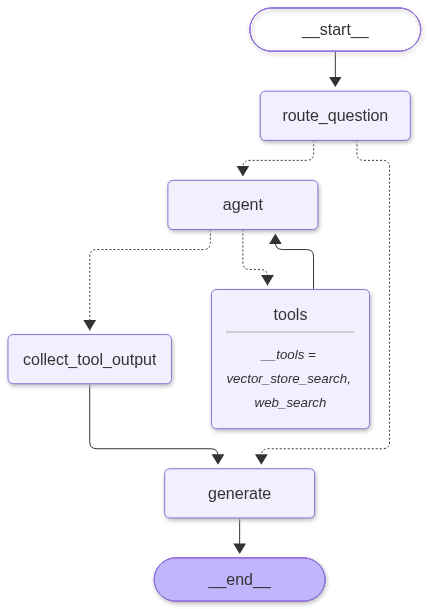

In [54]:
graph = graph_builder.compile()
graph

In [24]:
# Case 1: vector store only — domain-specific question about the PDF
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [25]:
print("=== CASE 1: Vector Store Only ===")
print(f"needs_retrieval : {result_vs['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_vs.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_vs.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_vs['generation']}")

=== CASE 1: Vector Store Only ===
needs_retrieval : True
retrieved_docs  : 5 docs
context preview : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
According to the report, the adoption of electric vehicles impacts oil demand primarily through "demand destruction," where fewer internal combustion engine (ICE) vehicles on the road results in fewer barrels of gasoline and diesel consumed, thereby reducing the total quantity of oil demanded at any given price. 

However, this impact is moderated by the "rebound effect," where reduced per-kilometer driving costs may encourage consumers to drive more kilometers, partially offsetting efficiency gains and recovering between 10 and 30 percent of direct savings. Additionally, accurately projecting oil demand displacement requires integrating three analytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing ICE fleet, and 

In [26]:
print(result_vs["context"])



## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 8
4. EV Adoption Trajectories and Oil Demand Displacement
 Projecting oil demand displacement from EV adoption requires integrating three distinct
analytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing
ICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.
The total stock of passenger vehicles globally stands at approximately 1.4 billion, the vast
majority of which are ICE vehicles. With global new vehicle sales of roughly 90 million units
per year and average vehicle lifetimes of 15 to 20 years in developed markets — and often
longer in developing markets — complete fleet electrification cannot occur in less than two to

reduce the total number of vehicles needed to satisfy mobility demand, compressing the size
of the vehicle stock through which electrification must diffuse.

In [ ]:
# Case 2: web search only — current information not in the PDF
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

In [25]:
print("=== CASE 2: Web Search Only ===")
print(f"needs_retrieval : {result_web['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_web.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_web.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_web['generation']}")

=== CASE 2: Web Search Only ===
needs_retrieval : True
retrieved_docs  : 10 docs
context preview : 

## Web Search Results





## Web Search Results

New Delhi, DL, IN Current Weather. New Delhi, DL, IN. Updated 6 minu...

Generation:
The current temperature in New Delhi is 28°C.


In [32]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai"

result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

In [33]:
print("=== CASE 3: Both Tools ===")
print(f"needs_retrieval : {result_both['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_both.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_both.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_both['generation']}")

=== CASE 3: Both Tools ===
needs_retrieval : True
retrieved_docs  : 10 docs
context preview : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
Report: the provided EV report excerpts do not give a numeric 2030 global oil‑demand figure. Instead, its assessment for the early 2030s is qualitative: EV penetration becomes "economically material" in the early 2030s and will begin to reduce oil demand growth (first and most in advanced economies), but the report says the full oil‑price shock dampening dividend will be most pronounced after 2035. It also warns the 2024–2035 transition period may still be a time of elevated oil‑price risk (EVs reduce demand growth but do not yet provide a large buffer vs. supply shocks), and recommends pursuing EVs alongside other hedging measures (strategic reserves, efficiency, fuel switching).

Mumbai weather (from the provided data, local time 2026-04-23 16:31):
- Curren

In [34]:
print(result_both["context"])



## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 8
4. EV Adoption Trajectories and Oil Demand Displacement
 Projecting oil demand displacement from EV adoption requires integrating three distinct
analytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing
ICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.
The total stock of passenger vehicles globally stands at approximately 1.4 billion, the vast
majority of which are ICE vehicles. With global new vehicle sales of roughly 90 million units
per year and average vehicle lifetimes of 15 to 20 years in developed markets — and often
longer in developing markets — complete fleet electrification cannot occur in less than two to

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 15
 The net assessment is that EV adoption is a

In [28]:
# Case 4: no retrieval — answerable from general knowledge
query_none = "Explain the difference between kinetic energy and potential energy."

result_none = graph.invoke({"query": query_none, "messages": [], "retrieved_docs": [], "context": ""})

In [30]:
print("=== CASE 4: No Retrieval ===")
print(f"needs_retrieval : {result_none['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_none.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_none.get('context', '') or '(none)'}")
print(f"\nGeneration:\n{result_none['generation']}")

=== CASE 4: No Retrieval ===
needs_retrieval : False
retrieved_docs  : 0 docs
context preview : (none)

Generation:
Here is an explanation of the difference between kinetic energy and potential energy.

### 1. Kinetic Energy
**Definition:** Kinetic energy is the energy of **motion**. An object possesses kinetic energy whenever it is moving.
*   **Dependency:** It depends on the mass of the object and its velocity (speed).
*   **Formula:** $KE = \frac{1}{2}mv^2$
*   **Examples:** A car driving down a road, a ball rolling across the floor, wind blowing, or electricity flowing through a wire.

### 2. Potential Energy
**Definition:** Potential energy is **stored energy**. It is held by an object due to its position, arrangement, or state. It has the potential to be converted into kinetic energy later.
*   **Dependency:** It depends on factors like height (gravitational), tension (elastic), or chemical composition.
*   **Formula (Gravitational PE):** $PE = mgh$
*   **Examples:**
    *   *Gr

In [ ]:
result_both["messages"][0].tool_calls

In [32]:
result_vs

{'messages': [AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3.5:9b', 'created_at': '2026-11-19T09:00:22.14861Z', 'done': True, 'done_reason': 'stop', 'total_duration': 9174880500, 'load_duration': 20961750, 'prompt_eval_count': 623, 'prompt_eval_duration': 3737455834, 'eval_count': 159, 'eval_duration': 5410447791, 'logprobs': None, 'model_name': 'qwen3.5:9b', 'model_provider': 'ollama'}, id='lc_run--01a1f308-f51e-7479-ac25-4fdb8766c577-0', tool_calls=[{'name': 'vector_store_search', 'args': {'k': 5, 'query': 'electric vehicle adoption impact oil demand displacement scenarios fleet turnover dynamics'}, 'id': 'c2274027-9f93-48ff-95e5-8b4c61f80700', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 623, 'output_tokens': 159, 'total_tokens': 782}),
  ToolMessage(content='\n\n## Vector Store Results\n\nWill EVs Dampen the Oil Price Shock?\nVersion 1.0\nResearch Report — For Educational and RAG Pipeline Use\nPage 8\n4. EV Adoption T

In [36]:
result_vs["messages"]

[AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3.5:9b', 'created_at': '2026-11-19T09:00:22.14861Z', 'done': True, 'done_reason': 'stop', 'total_duration': 9174880500, 'load_duration': 20961750, 'prompt_eval_count': 623, 'prompt_eval_duration': 3737455834, 'eval_count': 159, 'eval_duration': 5410447791, 'logprobs': None, 'model_name': 'qwen3.5:9b', 'model_provider': 'ollama'}, id='lc_run--01a1f308-f51e-7479-ac25-4fdb8766c577-0', tool_calls=[{'name': 'vector_store_search', 'args': {'k': 5, 'query': 'electric vehicle adoption impact oil demand displacement scenarios fleet turnover dynamics'}, 'id': 'c2274027-9f93-48ff-95e5-8b4c61f80700', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 623, 'output_tokens': 159, 'total_tokens': 782}),
 ToolMessage(content='\n\n## Vector Store Results\n\nWill EVs Dampen the Oil Price Shock?\nVersion 1.0\nResearch Report — For Educational and RAG Pipeline Use\nPage 8\n4. EV Adoption Trajectories an